In [35]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

In [36]:
true_counts = {
    "img_1.jpeg": 68,
    "img_2.jpeg": 23,
    "img_3.jpeg": 80,
    "img_4.jpg": 16,
    "img_5.jpg": 60,
}

def show(img_bgr, title="", grid=False, figsize=(10, 10), step=25):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title)
    if grid:
        h, w = img_bgr.shape[:2]
        ax = plt.gca()
        ax.set_xticks(range(0, w, step)); ax.set_yticks(range(0, h, step))
        ax.set_xticklabels([str(v) if v % 50 == 0 else "" for v in range(0, w, step)])
        ax.set_yticklabels([str(v) if v % 50 == 0 else "" for v in range(0, h, step)])
        ax.grid(True, alpha=0.4, color="yellow", linewidth=0.6)
    else:
        plt.axis("off")
    plt.show()

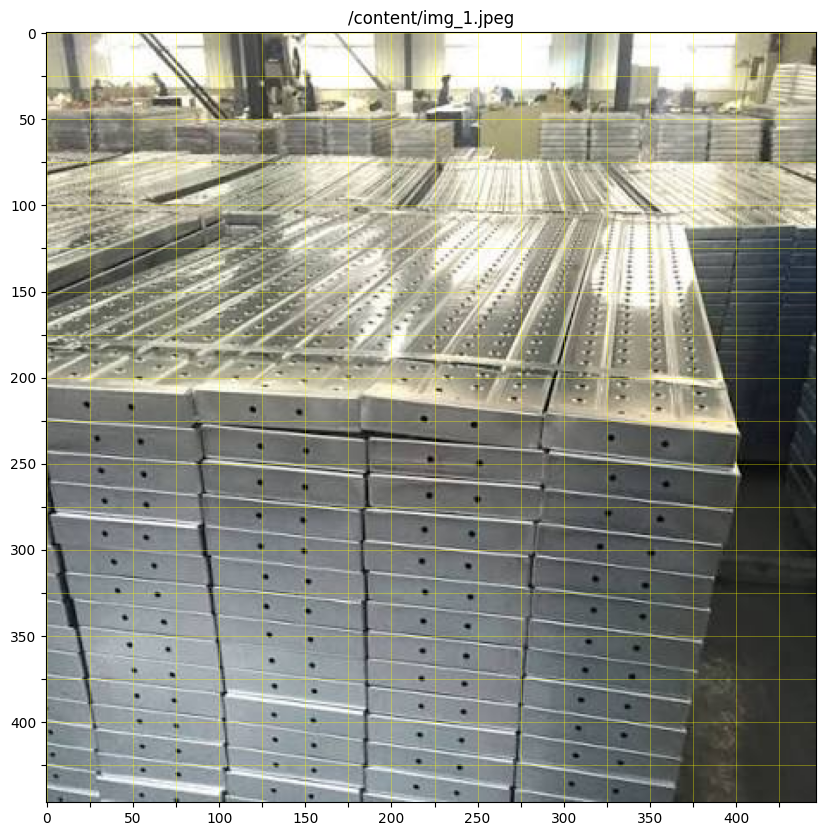

In [37]:
path = "/content/img_1.jpeg"
img = cv2.imread(path)
assert img is not None, f"Could not read {path}"
show(img, path, grid=True)

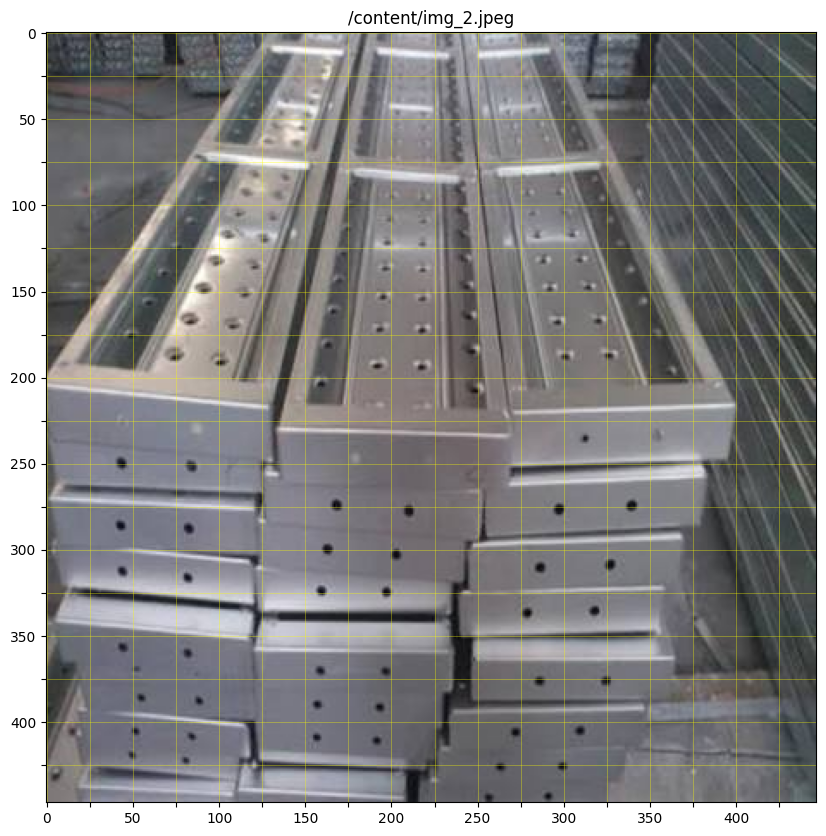

In [38]:
path = "/content/img_2.jpeg"
img = cv2.imread(path)
assert img is not None, f"Could not read {path}"
show(img, path, grid=True)

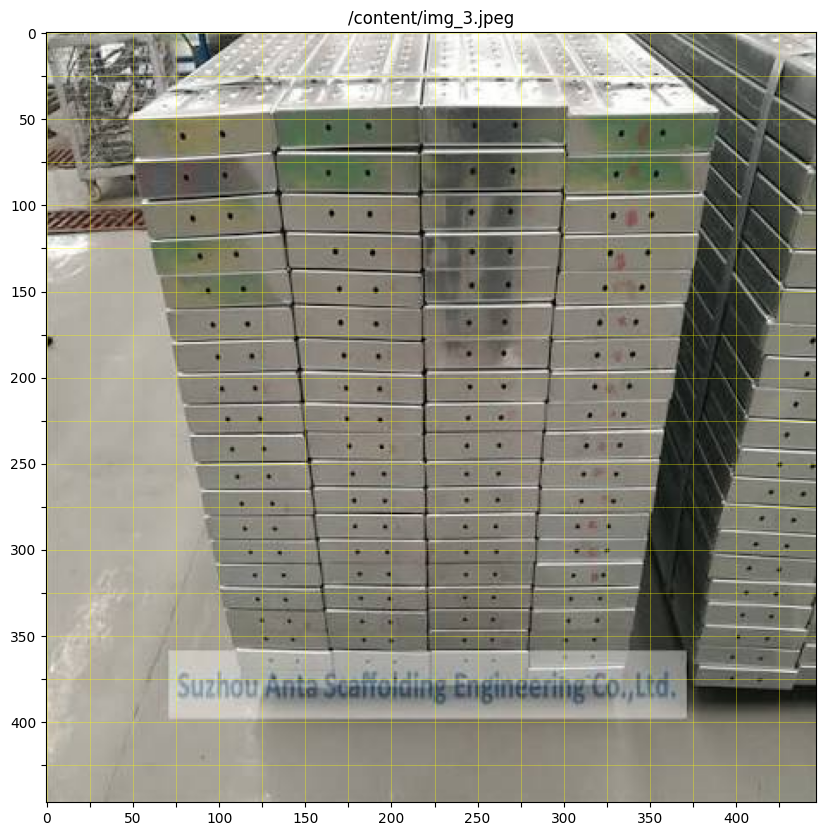

In [39]:
path = "/content/img_3.jpeg"
img = cv2.imread(path)
assert img is not None, f"Could not read {path}"
show(img, path, grid=True)

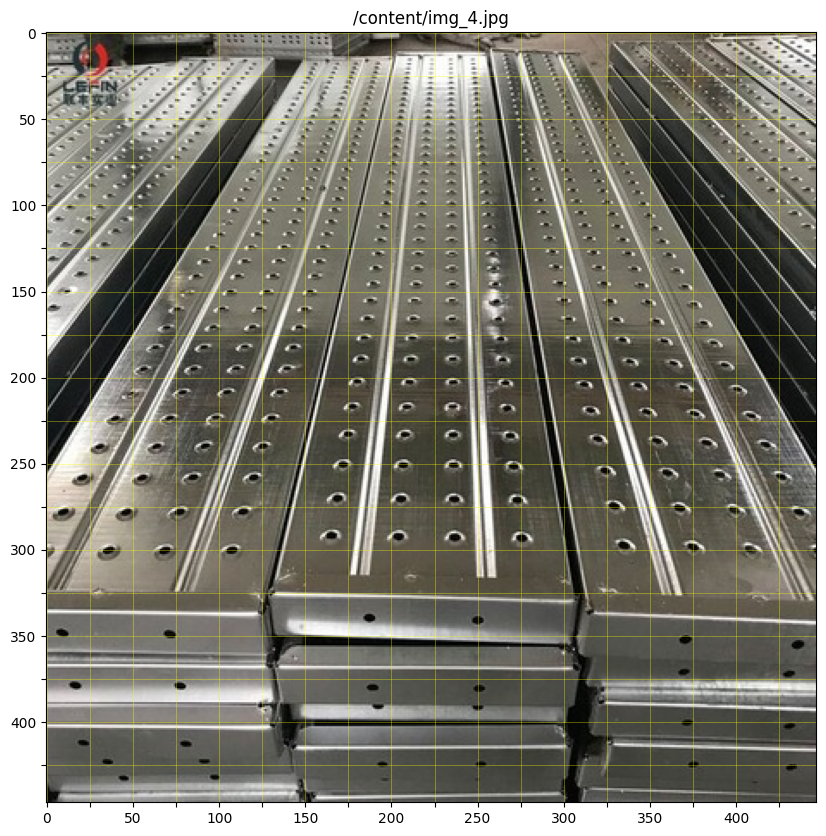

In [40]:
path = "/content/img_4.jpg"
img = cv2.imread(path)
assert img is not None, f"Could not read {path}"
show(img, path, grid=True)

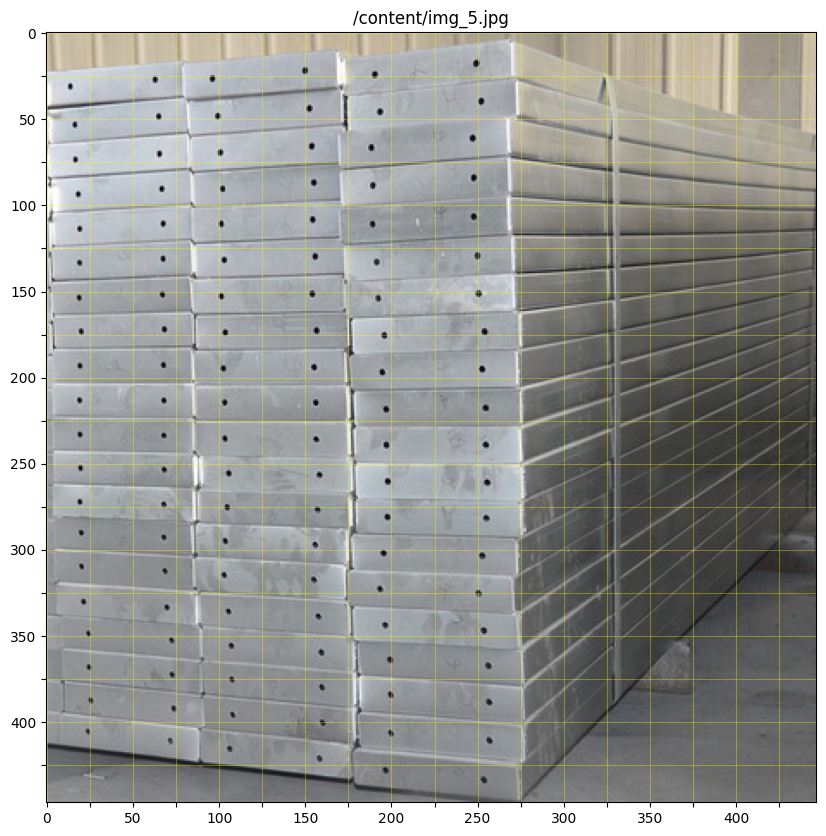

In [41]:
path = "/content/img_5.jpg"
img = cv2.imread(path)
assert img is not None, f"Could not read {path}"
show(img, path, grid=True)

In [42]:
corners = {
    "img_1.jpeg": [[0, 200], [400, 225], [360, 447], [25, 447]],
    "img_2.jpeg": [[0, 200], [400, 220], [330, 430], [25, 425]],
    "img_3.jpeg": [[50, 50], [380, 50], [335, 375], [110, 375]],
    "img_4.jpg": [[0, 325], [447, 325], [447, 440], [10, 440]],
    "img_5.jpg": [[0, 25], [275, 5], [275, 447], [0, 410]],
}

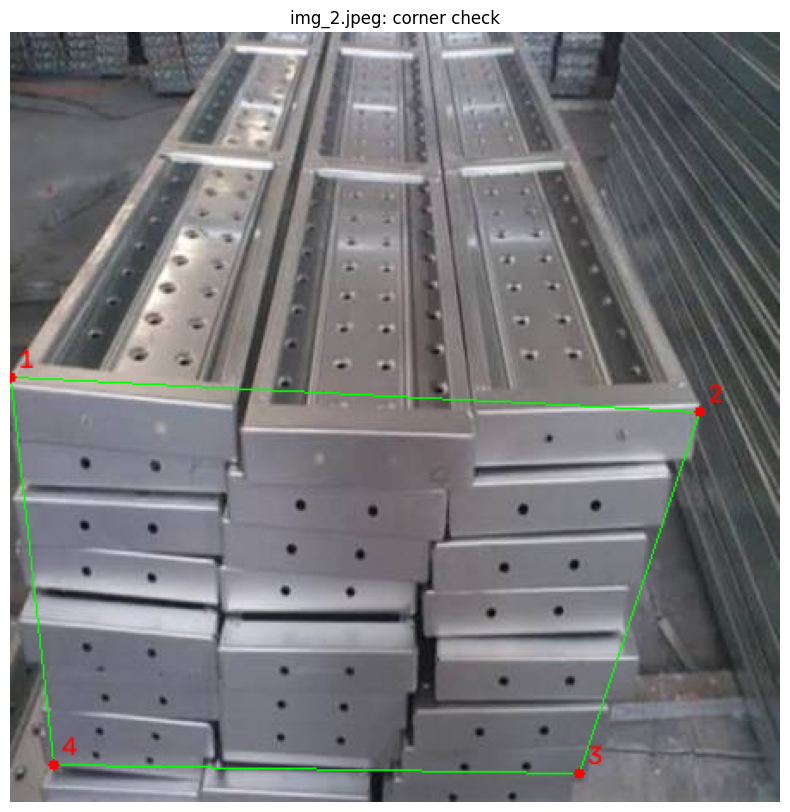

In [43]:
def check_corners(path):
    img = cv2.imread(path)
    pts = np.array(corners[path], dtype=np.int32)
    cv2.polylines(img, [pts], isClosed=True, color=(0, 255, 0), thickness=1)
    for i, (x, y) in enumerate(pts, 1):
        cv2.circle(img, (int(x), int(y)), 3, (0, 0, 255), -1)
        cv2.putText(img, str(i), (int(x) + 5, int(y) - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 255), 1)
    show(img, f"{path}: corner check")

check_corners("img_2.jpeg")

In [44]:
def get_profile(path, invert=False, blur=5, trim=0.1):
    flat = rectify(path)
    gray = cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY)
    gray = cv2.GaussianBlur(gray, (blur, blur), 0)
    h, w = gray.shape
    core = gray[:, int(w * trim): int(w * (1 - trim))]
    profile = core.mean(axis=1)
    profile = (profile - profile.min()) / (np.ptp(profile) + 1e-6)
    return 1 - profile if invert else profile

In [45]:
SCALE = 3   # upscale factor applied to every image's face size

def face_size(path):
    tl, tr, br, bl = [np.array(p, dtype=float) for p in corners[path]]
    width  = (np.linalg.norm(tr - tl) + np.linalg.norm(br - bl)) / 2
    height = (np.linalg.norm(bl - tl) + np.linalg.norm(br - tr)) / 2
    return width, height

def get_size(path):
    w, h = face_size(path)
    return int(w * SCALE), int(h * SCALE)

In [46]:
def rectify(path):
    w, h = get_size(path)
    img = cv2.imread(path)
    src = np.float32(corners[path])
    dst = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    return cv2.warpPerspective(img, cv2.getPerspectiveTransform(src, dst), (w, h))

def draw_dots(path, peaks, save=True, display=True):
    w, h = get_size(path)
    img = cv2.imread(path)
    src = np.float32(corners[path])
    dst = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    Minv = cv2.getPerspectiveTransform(dst, src)

    peaks = np.asarray(peaks)
    if len(peaks):
        flat_pts = np.float32([[[0.5 * w, y]] for y in peaks])
        pts = cv2.perspectiveTransform(flat_pts, Minv).reshape(-1, 2).astype(int)
    else:
        pts = []

    for i, (x, y) in enumerate(pts, start=1):
        cv2.circle(img, (int(x), int(y)), 4, (0, 255, 0), -1)
        cv2.putText(img, str(i), (int(x) + 6, int(y) + 4),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 255), 1)
    cv2.putText(img, f"Count: {len(peaks)}", (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)
    if save:
        cv2.imwrite("marked_" + path, img)
    if display:
        show(img, f"{path}: {len(peaks)} planks")
    return img

In [47]:
from scipy.ndimage import uniform_filter1d

def estimate_period(profile, min_lag=3):
    # remove slow lighting gradients so only the plank pattern remains
    p = profile - uniform_filter1d(profile, size=max(15, len(profile) // 5))
    p = p - p.mean()

    ac = np.correlate(p, p, mode="full")[len(p) - 1:]
    ac = ac / (ac[0] + 1e-9)                      # shift 0 = 1.0

    max_lag = len(p) // 2
    pk, _ = find_peaks(ac[:max_lag], prominence=0.05)
    pk = pk[pk >= min_lag]
    period = int(pk[0]) if len(pk) else None
    return period, ac

  column 1: period=11, distance=6, dips=29, planks=30


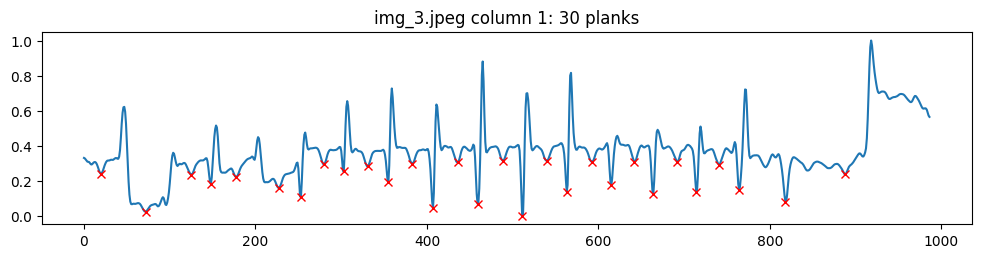

  column 2: period=12, distance=7, dips=29, planks=30


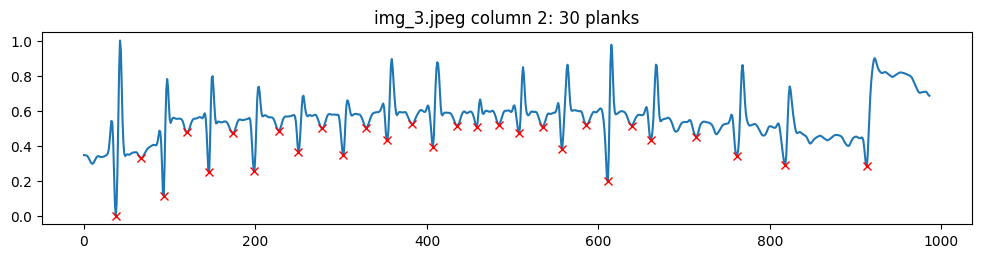

  column 3: period=10, distance=6, dips=27, planks=28


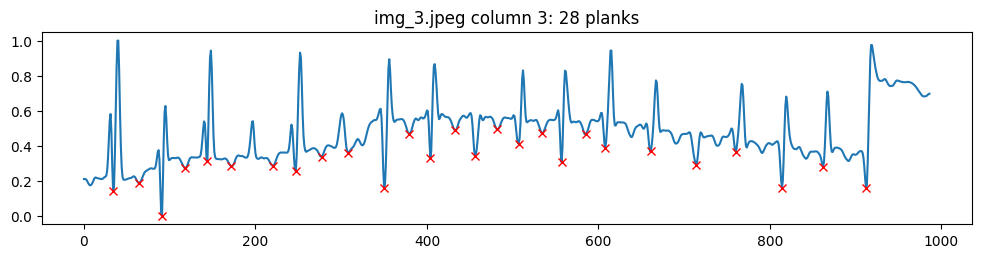

  column 4: period=52, distance=31, dips=14, planks=15


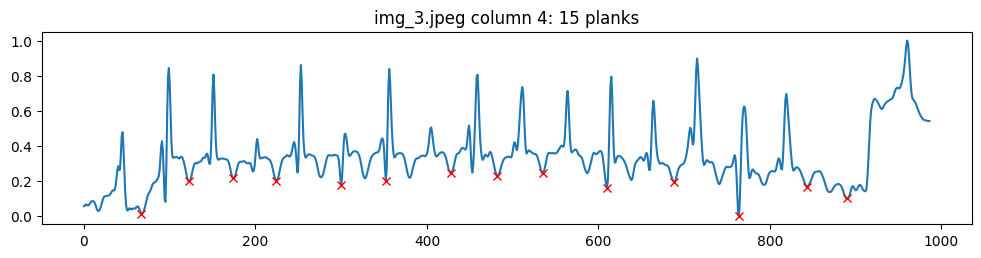

img_3.jpeg: total 103 (hand count 80)


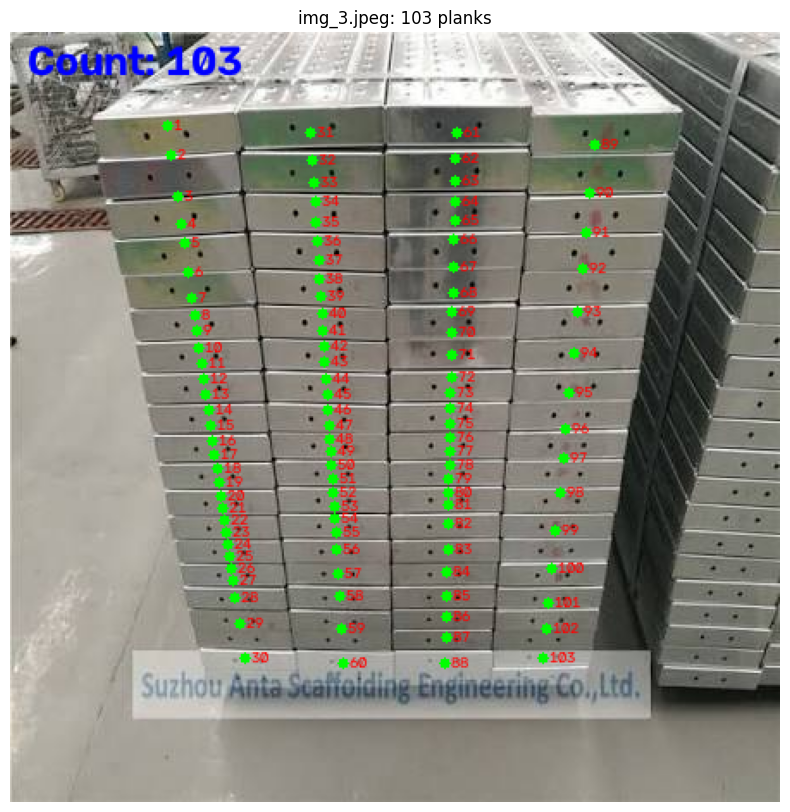

In [48]:
def count_columns(path, col_edges, dip_dist=None, prominence=0.08, trim=0.15, plot=True):
    flat = rectify(path)
    gray = cv2.GaussianBlur(cv2.cvtColor(flat, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    h, w = gray.shape
    all_centers = []   # (x_center, y_center) per plank, in rectified coordinates

    for i in range(len(col_edges) - 1):
        x0, x1 = col_edges[i], col_edges[i + 1]
        pad = int((x1 - x0) * trim)
        prof = gray[:, x0 + pad: x1 - pad].mean(axis=1)
        prof = (prof - prof.min()) / (np.ptp(prof) + 1e-6)

        period, _ = estimate_period(prof)
        d = dip_dist or (max(5, int(0.6 * period)) if period else 20)

        # gaps between planks are sharp DARK dips, so find valleys
        dips, _ = find_peaks(-prof, distance=d, prominence=prominence)
        bounds = [0] + list(dips) + [h]
        centers = [(bounds[j] + bounds[j + 1]) / 2 for j in range(len(bounds) - 1)]
        all_centers += [((x0 + x1) / 2, c) for c in centers]
        print(f"  column {i+1}: period={period}, distance={d}, dips={len(dips)}, planks={len(centers)}")

        if plot:
            plt.figure(figsize=(12, 2.5))
            plt.plot(prof); plt.plot(dips, prof[dips], "rx")
            plt.title(f"{path} column {i+1}: {len(centers)} planks"); plt.show()

    print(f"{path}: total {len(all_centers)} (hand count {true_counts.get(path)})")
    return all_centers

def draw_dots_xy(path, centers, save=True):
    w, h = get_size(path)
    img = cv2.imread(path)
    src = np.float32(corners[path])
    dst = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    Minv = cv2.getPerspectiveTransform(dst, src)
    pts = cv2.perspectiveTransform(np.float32([[c] for c in centers]), Minv).reshape(-1, 2)
    for i, (x, y) in enumerate(pts, 1):
        cv2.circle(img, (int(x), int(y)), 3, (0, 255, 0), -1)
        cv2.putText(img, str(i), (int(x) + 4, int(y) + 3),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.3, (0, 0, 255), 1)
    cv2.putText(img, f"Count: {len(centers)}", (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 0, 0), 2)
    if save: cv2.imwrite("marked_" + path, img)
    show(img, f"{path}: {len(centers)} planks")

w, h = get_size("img_3.jpeg")
col_edges = [0, 205, 420, 635, w]          # adjust to your rectified image
centers = count_columns("img_3.jpeg", col_edges)
draw_dots_xy("img_3.jpeg", centers)